# MeanFlow：从恒等式到一步生成的二维实验

本 notebook 将原来单个 Markdown 中的公式和代码整理成可顺序运行的实验，统一采用

$$x_0\sim\mathcal N(0,I)\longrightarrow x_1\sim p_{\mathrm{data}},\qquad t:0\to1.$$

实验分为五部分：

1. 在线性 ODE 上验证 MeanFlow 恒等式与 JVP 符号；
2. 在二维八高斯上从零训练 MeanFlow 与标准 Flow Matching；
3. 比较一步和多步生成的 MMD、Sliced Wasserstein；
4. 检查直接流映射与递推子区间映射的一致性；
5. 对非对角时间、JVP 方向和自适应权重做消融，并在已知流映射上监督验证平均速度。

MeanFlow 的训练 loss 与 FM loss 尺度不同，模型优劣以统一的生成分布指标为准。

## 1. MeanFlow 恒等式

定义从 $s$ 到固定终点 $t$ 的平均速度

$$
u(x_s,s,t)=\frac{x_t-x_s}{t-s},
\qquad x_t=x_s+(t-s)u(x_s,s,t).
$$

沿 ODE 轨迹改变 $s$、保持 $t$ 不变，对上式求导可得

$$
u=v+(t-s)\left(\partial_xu\,v+\partial_su\right).
$$

如果网络使用 $(x,s,\Delta)$ 且 $\Delta=t-s$，保持 $t$ 不变意味着 JVP 方向为

$$
(v,1,-1),
$$

因此

$$
\boxed{u=v+\Delta\,\operatorname{JVP}_{(v,1,-1)}u}.
$$

下面先在 $\dot x=Ax$ 上用解析矩阵指数验证这个恒等式。

In [1]:
from pathlib import Path
import copy
import json
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# 固定随机种子，使模型初始化、训练 batch 和评价样本可以复现。
SEED = 42
# 优先使用 GPU；所有训练张量都通过 DEVICE 放到同一设备。
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
OUTPUT_DIR = Path("meanflow_outputs")
# 图片、数值指标和模型权重统一保存在 notebook 同级目录。
OUTPUT_DIR.mkdir(exist_ok=True)


def set_seed(seed=SEED):
    """同时固定 Python、NumPy、CPU PyTorch 和 CUDA 的随机状态。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.22})
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR.resolve())

PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/meanflow_outputs


In [2]:
# 使用 float64，使解析恒等式误差接近机器精度。
A64 = torch.tensor([[0.5, -1.0], [1.0, 0.2]], dtype=torch.float64)


def linear_velocity64(x):
    """线性 ODE dx/dt=A x 的瞬时速度；样本按行存储。"""
    return x@A64.T


def exact_linear_flow64(x, s, t):
    """解析流映射 Phi_{t<-s}(x)=exp(A(t-s))x。"""
    transition = torch.matrix_exp(A64*(t-s))
    return x@transition.T


def exact_average_velocity64(x, s, t):
    """由净位移除以时间间隔得到精确平均速度。"""
    return (exact_linear_flow64(x, s, t)-x)/(t-s)


set_seed(SEED)
identity_x = torch.randn(256, 2, dtype=torch.float64)
identity_s = torch.tensor(0.2, dtype=torch.float64)
identity_t = torch.tensor(0.9, dtype=torch.float64)
instantaneous_v = linear_velocity64(identity_x)
# 这里函数的三个输入是 (x, s, t)，目标时间 t 固定。
# torch.func.jvp(func, primals, tangents) 返回：
#   1) func(*primals)，即当前点的平均速度 u；
#   2) d/dε func(x+εv, s+ε, t)|_{ε=0}，即沿 (v,1,0) 的方向导数。
# 因为坐标直接使用 t，所以固定 t 对应第三个 tangent=0。
average_u, directional_du = torch.func.jvp(
    exact_average_velocity64,
    (identity_x, identity_s, identity_t),
    (instantaneous_v, torch.ones_like(identity_s), torch.zeros_like(identity_t)),
)
# 检查 u = v + (t-s) D_s u。
identity_target = instantaneous_v+(identity_t-identity_s)*directional_du
identity_error = float((average_u-identity_target).abs().max())
# 平均速度的定义还应精确满足 x_t=x_s+(t-s)u。
reconstructed = identity_x+(identity_t-identity_s)*average_u
endpoint_error = float((reconstructed-exact_linear_flow64(identity_x, identity_s, identity_t)).abs().max())
print(f"MeanFlow identity max error       : {identity_error:.3e}")
print(f"Endpoint reconstruction max error: {endpoint_error:.3e}")

MeanFlow identity max error       : 2.665e-15
Endpoint reconstruction max error: 4.441e-16


## 2. 八高斯目标、网络与时间采样

目标分布是半径 4 圆周上的八个等权高斯：

$$
p_1(x)=\frac18\sum_{k=0}^7\mathcal N(x;\mu_k,0.3^2I),
\qquad
\mu_k=4(\cos(2\pi k/8),\sin(2\pi k/8)).
$$

网络输入当前状态 $x_s$、起始时间 $s$ 和区间长度 $\Delta=t-s$。部分样本取 $\Delta=0$ 训练瞬时速度，部分样本取 $\Delta>0$ 训练有限区间平均速度。

训练使用条件直线 $x_s=(1-s)x_0+sx_1$ 和条件速度 $V=x_1-x_0$。MeanFlow 的停止梯度目标为

$$
u_{\mathrm{target}}
=\operatorname{sg}\!\left[V+\Delta\operatorname{JVP}_{(V,1,-1)}u_\theta\right].
$$

In [3]:
BATCH_SIZE = 512
TRAIN_STEPS = 4_000
LEARNING_RATE = 1e-3
HIDDEN_DIM = 128
NUM_LAYERS = 3
OFF_DIAG_PROB = 0.25
LOSS_P = 1.0
LOSS_C = 0.01


def sample_data(batch_size):
    """从圆周上八个等权二维高斯分量采样目标数据。"""
    component = torch.randint(0, 8, (batch_size,), device=DEVICE)
    angle = 2*math.pi*component.float()/8
    centers = 4*torch.stack([torch.cos(angle), torch.sin(angle)], dim=-1)
    return centers+0.3*torch.randn(batch_size, 2, device=DEVICE)


def sample_noise(batch_size):
    """采样源分布 x0~N(0,I)。"""
    return torch.randn(batch_size, 2, device=DEVICE)


# 时间编码同时保留原始标量和多频率正余弦特征。
class TimeEmbedding(nn.Module):
    def __init__(self, num_frequencies=8):
        super().__init__()
        self.register_buffer("frequencies", 2**torch.arange(num_frequencies, dtype=DTYPE))

    def forward(self, t):
        angles = 2*math.pi*t*self.frequencies
        return torch.cat([t, torch.sin(angles), torch.cos(angles)], dim=-1)


# 网络预测 u_theta(x_s, s, delta)，其中 delta=t-s。
class MeanFlowNet(nn.Module):
    def __init__(self, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS):
        super().__init__()
        self.time_embedding = TimeEmbedding(8)
        layers = []
        current_dim = 2+17+17
        for _ in range(num_layers):
            layers.extend([nn.Linear(current_dim, hidden_dim), nn.SiLU()])
            current_dim = hidden_dim
        layers.append(nn.Linear(current_dim, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x, s, delta):
        """x:[B,2]，s/delta:[B,1]，输出区间平均速度 [B,2]。"""
        return self.net(torch.cat([
            x, self.time_embedding(s), self.time_embedding(delta)
        ], dim=-1))


def sample_times(batch_size, off_diagonal_probability):
    """采样 s<=t，并按概率把样本保留为非对角区间。

    非对角样本 delta>0，训练有限区间平均速度；其余样本令 t=s、delta=0，
    此时 MeanFlow 目标退化为标准瞬时速度目标。
    """
    first = torch.rand(batch_size, 1, device=DEVICE)
    second = torch.rand(batch_size, 1, device=DEVICE)
    s = torch.minimum(first, second)
    t = torch.maximum(first, second)
    use_off_diagonal = torch.rand(batch_size, 1, device=DEVICE) < off_diagonal_probability
    # mask=False 时强制 t=s，从而得到对角线训练样本。
    t = torch.where(use_off_diagonal, t, s)
    return s, t-s

In [4]:
def meanflow_loss(
    model, x0, x1, off_diagonal_probability=OFF_DIAG_PROB,
    loss_power=LOSS_P, wrong_jvp=False,
):
    """计算一个 batch 的 MeanFlow bootstrap 损失。

    网络坐标采用 (x_s, s, delta)，其中 delta=t-s。MeanFlow 恒等式为

        u = V + delta * D_s u,

    而 D_s u 是“固定目标时间 t，沿轨迹增加起始时间 s”的全导数。
    """
    # 采样 s 和 delta。对角线样本 delta=0；非对角样本 delta>0。
    s, delta = sample_times(len(x0), off_diagonal_probability)

    # 条件直线插值及样本级条件速度。
    # detach 表示它们只是训练数据，不需要把梯度传播到 x0/x1 的构造过程。
    xs = ((1-s)*x0+s*x1).detach()
    conditional_velocity = (x1-x0).detach()

    # ------------------------------------------------------------------
    # JVP 方向为什么是 (V, 1, -1)？
    # ------------------------------------------------------------------
    # 网络输入是 (x_s, s, delta)，但数学推导要求“保持目标时间 t 固定”。
    # 当 s 增加一个微小量 ε 时：
    #   x_s -> x_s + ε V        （沿条件速度移动）
    #   s   -> s + ε            （起始时间增加）
    #   delta=t-s -> delta-ε     （因为 t 固定，所以区间长度减少）
    # 因此正确 tangent 为 (V, 1, -1)，JVP 计算
    #
    #   J_x u · V + partial_s u - partial_delta u.
    #
    # 如果网络直接输入 (x,s,t)，同一导数方向才会写成 (V,1,0)。
    if wrong_jvp:
        # 消融：只保留空间方向 J_x u·V，故意遗漏两个时间导数。
        tangent = (
            conditional_velocity,
            torch.zeros_like(s),
            torch.zeros_like(delta),
        )
    else:
        tangent = (
            conditional_velocity,
            torch.ones_like(s),
            -torch.ones_like(delta),
        )

    # primals 与 tangents 按位置一一对应：
    #   primals  = (xs, s, delta)
    #   tangents = (V,  1,   -1)
    # torch.func.jvp 返回二元组：
    #   prediction            = u_theta(xs,s,delta)
    #   directional_derivative= d/dε u_theta(xs+εV,s+ε,delta-ε)|_{ε=0}
    # forward-mode JVP 直接计算 Jacobian-vector product，无需显式构造巨大 Jacobian。
    prediction, directional_derivative = torch.func.jvp(
        lambda x, start, span: model(x, start, span),
        (xs, s, delta),
        tangent,
    )

    # 用当前网络的方向导数构造 bootstrap target。
    # directional_derivative 本来仍依赖模型参数；对整个 target 调用 detach 后，
    # 反向传播只通过 prediction 分支更新参数，不会穿过 target/JVP 分支。
    # 这正是公式中的 stop-gradient sg(.)。
    target = (conditional_velocity+delta*directional_derivative).detach()

    # 先按样本、再按输出维度求均方误差。
    per_sample_error = (prediction-target).square().mean(dim=-1)

    # 自适应权重降低大残差样本的影响。权重本身也 detach，防止网络通过改变
    # 权重而非减小残差来优化目标；loss_power=0 时退化为普通 MSE。
    weight = (per_sample_error.detach()+LOSS_C).pow(-loss_power)
    return (weight*per_sample_error).mean()


def flow_matching_loss(model, x0, x1):
    """标准 FM 基线：只调用 delta=0 的瞬时速度分支。"""
    s = torch.rand(len(x0), 1, device=DEVICE)
    xs = (1-s)*x0+s*x1
    prediction = model(xs, s, torch.zeros_like(s))
    return F.mse_loss(prediction, x1-x0)


def train_model(
    name, base_state, steps=TRAIN_STEPS, off_diagonal_probability=OFF_DIAG_PROB,
    loss_power=LOSS_P, wrong_jvp=False, use_fm_loss=False, seed=SEED+100,
):
    """从相同初始权重训练一个配置，并返回模型与逐步 loss。"""
    # 每个消融重置同一随机种子，使初始权重、数据 batch 和时间样本尽量公平。
    set_seed(seed)
    model = MeanFlowNet().to(DEVICE)
    model.load_state_dict(base_state)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
    losses = []
    model.train()
    for step in range(1, steps+1):
        x0, x1 = sample_noise(BATCH_SIZE), sample_data(BATCH_SIZE)
        if use_fm_loss:
            loss = flow_matching_loss(model, x0, x1)
        else:
            loss = meanflow_loss(
                model, x0, x1, off_diagonal_probability, loss_power, wrong_jvp
            )
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        # JVP bootstrap 偶尔会产生大梯度，裁剪用于限制单步参数更新。
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        losses.append(float(loss.detach()))
        if step == 1 or step % 500 == 0:
            print(f"{name:<18} step {step:4d}/{steps}: avg loss={np.mean(losses[-200:]):.6f}")
    return model.eval(), losses

## 3. 主实验与三项消融

所有模型使用相同初始参数、网络规模、训练步数和随机批次：

| 模型 | 设置 | 检查内容 |
|---|---|---|
| MeanFlow | $P(s<t)=0.25,p=1$，正确 JVP | 主模型 |
| FM | 仅瞬时速度监督 | 一步与多步基线 |
| Wrong JVP | 使用 $(V,0,0)$ | 时间方向导数是否必要 |
| Diagonal only | $P(s<t)=0$ | 只学瞬时速度能否泛化到完整区间 |
| Unweighted | $p=0$ | 自适应残差权重的作用 |

其中 `Diagonal only` 在训练时从未看到 $Delta>0$，但一步推理需要 $Delta=1$，因此它也是一个外推失败对照。

In [5]:
# 创建一次公共初始化；五个模型都从完全相同的参数开始。
set_seed(SEED+10)
initial_model = MeanFlowNet().to(DEVICE)
base_state = copy.deepcopy(initial_model.state_dict())
training_seed = SEED+200
started = time.perf_counter()

# 主 MeanFlow：正确 JVP、25% 非对角样本、自适应权重 p=1。
meanflow_model, meanflow_losses = train_model(
    "MeanFlow", base_state, seed=training_seed
)
# 标准 FM：只监督 delta=0 的瞬时速度。
fm_model, fm_losses = train_model(
    "Flow Matching", base_state, use_fm_loss=True, seed=training_seed
)
# JVP 消融：遗漏时间方向导数。
wrong_jvp_model, wrong_jvp_losses = train_model(
    "Wrong JVP", base_state, wrong_jvp=True, seed=training_seed
)
# 时间采样消融：训练阶段从未见过 delta>0。
diagonal_model, diagonal_losses = train_model(
    "Diagonal only", base_state, off_diagonal_probability=0.0, seed=training_seed
)
# 权重消融：loss_power=0，使损失退化为普通 MSE。
unweighted_model, unweighted_losses = train_model(
    "Unweighted", base_state, loss_power=0.0, seed=training_seed
)
print(f"Total training time: {time.perf_counter()-started:.1f} s")

MeanFlow           step    1/4000: avg loss=0.998515


MeanFlow           step  500/4000: avg loss=0.983166


MeanFlow           step 1000/4000: avg loss=0.975408


MeanFlow           step 1500/4000: avg loss=0.971305


MeanFlow           step 2000/4000: avg loss=0.968718


...

Unweighted         step 2000/4000: avg loss=19759.502324


Unweighted         step 2500/4000: avg loss=1112454.013340


Unweighted         step 3000/4000: avg loss=135143.667979


Unweighted         step 3500/4000: avg loss=906907.216211


Unweighted         step 4000/4000: avg loss=11338218.417500
Total training time: 162.2 s


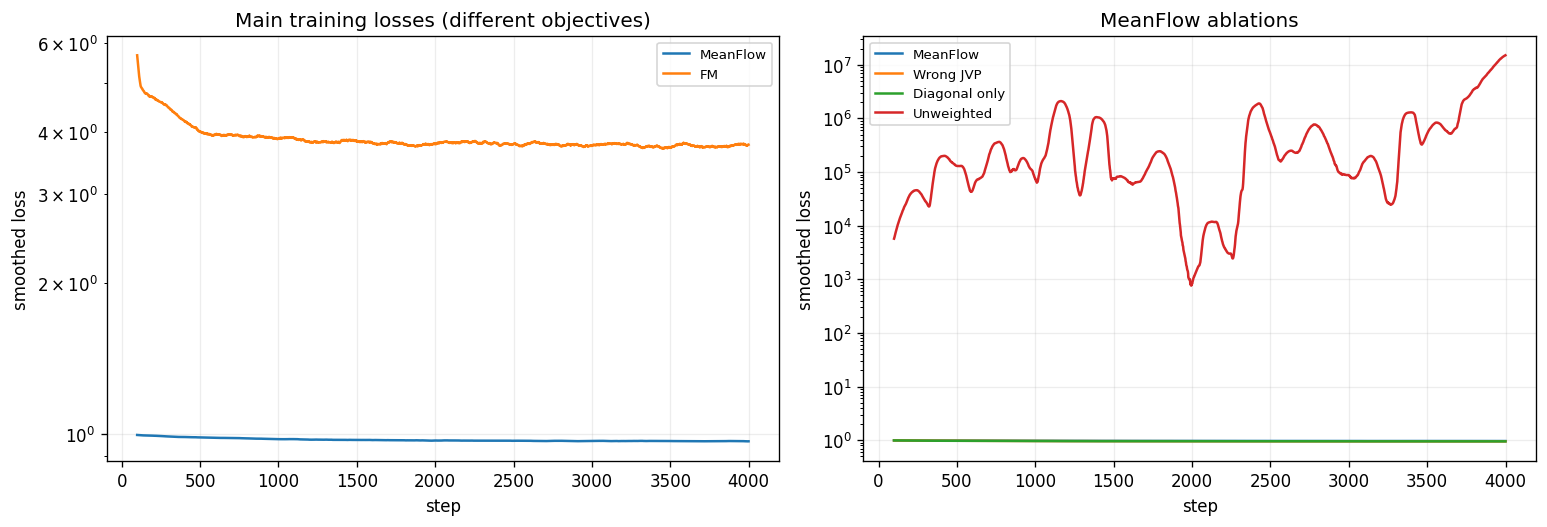

In [6]:
# 滑动平均仅用于提高曲线可读性，不参与训练或指标计算。
def smooth(values, window=100):
    values = np.asarray(values)
    return np.arange(window-1, len(values)), np.convolve(values, np.ones(window)/window, mode="valid")


loss_histories = {
    "MeanFlow": meanflow_losses,
    "FM": fm_losses,
    "Wrong JVP": wrong_jvp_losses,
    "Diagonal only": diagonal_losses,
    "Unweighted": unweighted_losses,
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in ["MeanFlow", "FM"]:
    x_axis, values = smooth(loss_histories[name])
    axes[0].plot(x_axis, values, label=name)
for name in ["MeanFlow", "Wrong JVP", "Diagonal only", "Unweighted"]:
    x_axis, values = smooth(loss_histories[name])
    axes[1].plot(x_axis, values, label=name)
for ax, title in zip(axes, ["Main training losses (different objectives)", "MeanFlow ablations"]):
    ax.set(title=title, xlabel="step", ylabel="smoothed loss", yscale="log")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_training_losses.png", dpi=170, bbox_inches="tight")
plt.show()

## 4. 一步、多步生成与统一分布指标

MeanFlow 用区间平均速度更新

$$x_{t_{i+1}}=x_{t_i}+\Delta t\,u_\theta(x_{t_i},t_i,\Delta t),$$

而 FM Euler 使用对角线瞬时速度

$$x_{t_{i+1}}=x_{t_i}+\Delta t\,v_\theta(x_{t_i},t_i).$$

所有方法使用同一批初始噪声和目标样本。报告多带宽 RBF MMD² 与固定投影方向的 Sliced Wasserstein，避免评价随机性混入方法差异。

In [7]:
@torch.no_grad()
def sample_meanflow(model, initial, steps=1, keep_path=False):
    """用每个子区间的平均速度更新；steps=1 即一次完整区间生成。"""
    x = initial.clone()
    path = [x.clone()] if keep_path else None
    dt = 1/steps
    for index in range(steps):
        s = torch.full((len(x), 1), index*dt, device=DEVICE)
        delta = torch.full_like(s, dt)
        # u 代表区间平均速度，乘区间长度 dt 得到该段净位移。
        x = x+dt*model(x, s, delta)
        if keep_path:
            path.append(x.clone())
    return torch.stack(path) if keep_path else x


@torch.no_grad()
def sample_fm(model, initial, steps=20, keep_path=False):
    """用 delta=0 的瞬时速度执行显式 Euler 积分。"""
    x = initial.clone()
    path = [x.clone()] if keep_path else None
    dt = 1/steps
    for index in range(steps):
        s = torch.full((len(x), 1), index*dt, device=DEVICE)
        x = x+dt*model(x, s, torch.zeros_like(s))
        if keep_path:
            path.append(x.clone())
    return torch.stack(path) if keep_path else x


@torch.no_grad()
def multiscale_mmd2(x, y, bandwidths=(0.25, 1.0, 4.0, 16.0)):
    """多带宽 RBF MMD²；同时覆盖簇内和簇间距离尺度。"""
    dxx, dyy, dxy = torch.cdist(x, x).square(), torch.cdist(y, y).square(), torch.cdist(x, y).square()
    value = 0.0
    for bandwidth in bandwidths:
        value += torch.exp(-dxx/(2*bandwidth)).mean()
        value += torch.exp(-dyy/(2*bandwidth)).mean()
        value -= 2*torch.exp(-dxy/(2*bandwidth)).mean()
    return float(value/len(bandwidths))


@torch.no_grad()
def sliced_wasserstein(x, y, directions):
    """投影到固定的一维方向，排序后计算经验 W1，再对方向平均。"""
    projected_x = torch.sort(x@directions.T, dim=0).values
    projected_y = torch.sort(y@directions.T, dim=0).values
    return float((projected_x-projected_y).abs().mean())

In [8]:
# 所有模型共享同一批源噪声、目标样本和投影方向，减少 Monte Carlo 差异。
set_seed(2026)
evaluation_count = 1_536
evaluation_noise = sample_noise(evaluation_count)
evaluation_target = sample_data(evaluation_count)
directions = torch.randn(256, 2, device=DEVICE)
# 每行归一化成二维单位方向，供所有 SWD 计算复用。
directions = directions/torch.linalg.norm(directions, dim=1, keepdim=True)

generated = {}
for steps in [1, 2, 4, 8, 16]:
    generated[f"MeanFlow-{steps}"] = sample_meanflow(meanflow_model, evaluation_noise, steps)
for steps in [1, 2, 4, 8, 16, 32]:
    generated[f"FM-{steps}"] = sample_fm(fm_model, evaluation_noise, steps)
generated["WrongJVP-1"] = sample_meanflow(wrong_jvp_model, evaluation_noise, 1)
generated["Diagonal-1"] = sample_meanflow(diagonal_model, evaluation_noise, 1)
generated["Unweighted-1"] = sample_meanflow(unweighted_model, evaluation_noise, 1)

distribution_metrics = {}
print(f"{'method':<16} {'MMD2':>11} {'SWD':>11}")
for name, samples in generated.items():
    row = {
        "mmd2": multiscale_mmd2(samples, evaluation_target),
        "swd": sliced_wasserstein(samples, evaluation_target, directions),
    }
    distribution_metrics[name] = row
    print(f"{name:<16} {row['mmd2']:11.6f} {row['swd']:11.6f}")

method                  MMD2         SWD


MeanFlow-1          0.035469    0.565420
MeanFlow-2          0.016285    0.404719
MeanFlow-4          0.018649    0.434954
MeanFlow-8          0.011655    0.277706
MeanFlow-16         0.010611    0.251104
FM-1                0.703850    2.383814
FM-2                0.051077    0.657981
FM-4                0.015021    0.346578
FM-8                0.006749    0.255009
FM-16               0.004909    0.235139
FM-32               0.003684    0.204753
WrongJVP-1          0.126368    0.990415
Diagonal-1          0.009108    0.295289
Unweighted-1        0.433747   66.491615


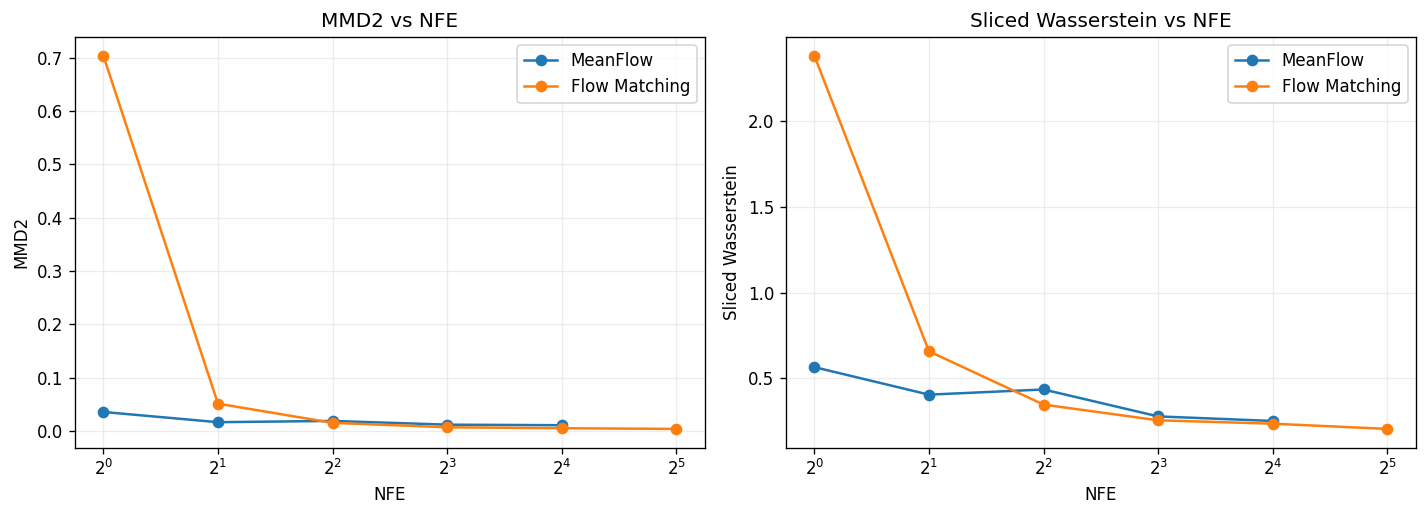

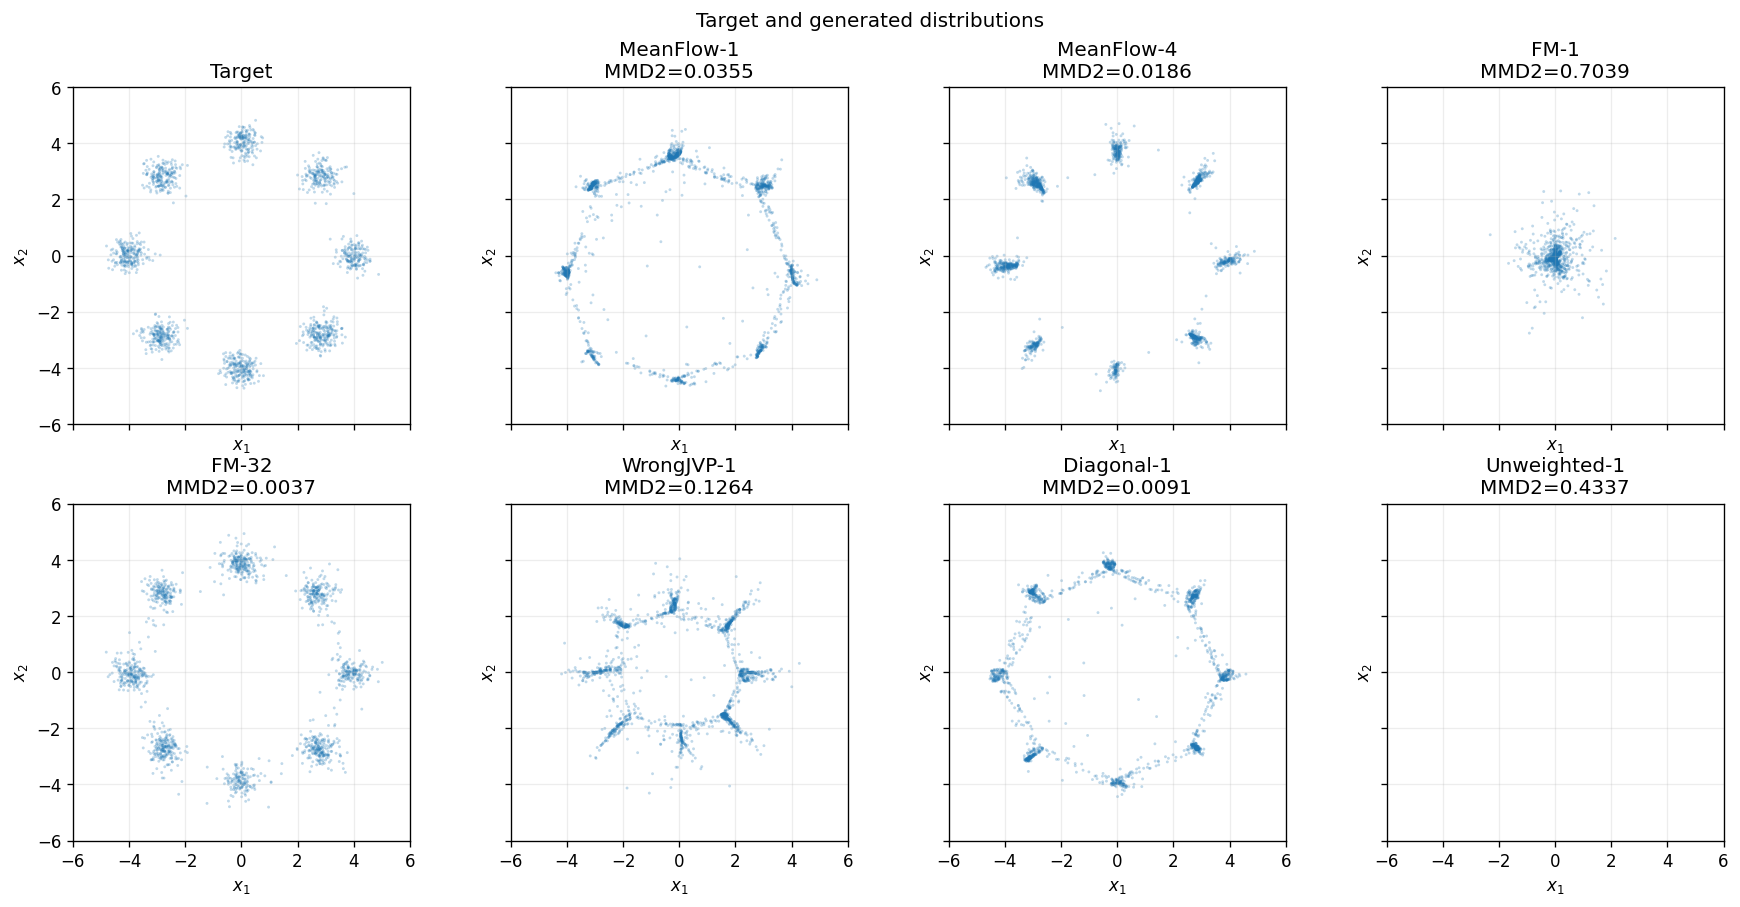

In [9]:
# 左图比较生成质量随 NFE 的变化；下方散点图使用统一坐标便于识别发散。
meanflow_steps = [1, 2, 4, 8, 16]
fm_steps = [1, 2, 4, 8, 16, 32]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, key, ylabel in zip(axes, ["mmd2", "swd"], ["MMD2", "Sliced Wasserstein"]):
    ax.plot(meanflow_steps, [distribution_metrics[f"MeanFlow-{n}"][key] for n in meanflow_steps], marker="o", label="MeanFlow")
    ax.plot(fm_steps, [distribution_metrics[f"FM-{n}"][key] for n in fm_steps], marker="o", label="Flow Matching")
    ax.set_xscale("log", base=2)
    ax.set(title=f"{ylabel} vs NFE", xlabel="NFE", ylabel=ylabel)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_quality_vs_nfe.png", dpi=170, bbox_inches="tight")
plt.show()

display_names = ["Target", "MeanFlow-1", "MeanFlow-4", "FM-1", "FM-32", "WrongJVP-1", "Diagonal-1", "Unweighted-1"]
display_values = [evaluation_target]+[generated[name] for name in display_names[1:]]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6), sharex=True, sharey=True)
for ax, name, points_tensor in zip(axes.flat, display_names, display_values):
    points = points_tensor.cpu().numpy()
    ax.scatter(points[:, 0], points[:, 1], s=3, alpha=0.28, edgecolors="none")
    title = name if name == "Target" else f"{name}\nMMD2={distribution_metrics[name]['mmd2']:.4f}"
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-6, 6), ylim=(-6, 6))
    ax.set_aspect("equal")
fig.suptitle("Target and generated distributions")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_generated_distributions.png", dpi=170, bbox_inches="tight")
plt.show()

## 5. 直接流映射与递推映射一致性

对相同的 $x_0$ 和时刻 $t_i$，比较

$$
x_{t_i}^{\mathrm{direct}}
=x_0+t_i u_\theta(x_0,0,t_i)
$$

与逐个子区间递推得到的 $x_{t_i}^{\mathrm{recursive}}$。精确流映射满足组合性质，两者应一致。

该误差只检查模型内部的区间映射一致性，不能替代 MMD 或 SWD。一个映射可以高度自洽，但输运到错误分布。

Direct vs recursive mean squared path error: 0.9912560


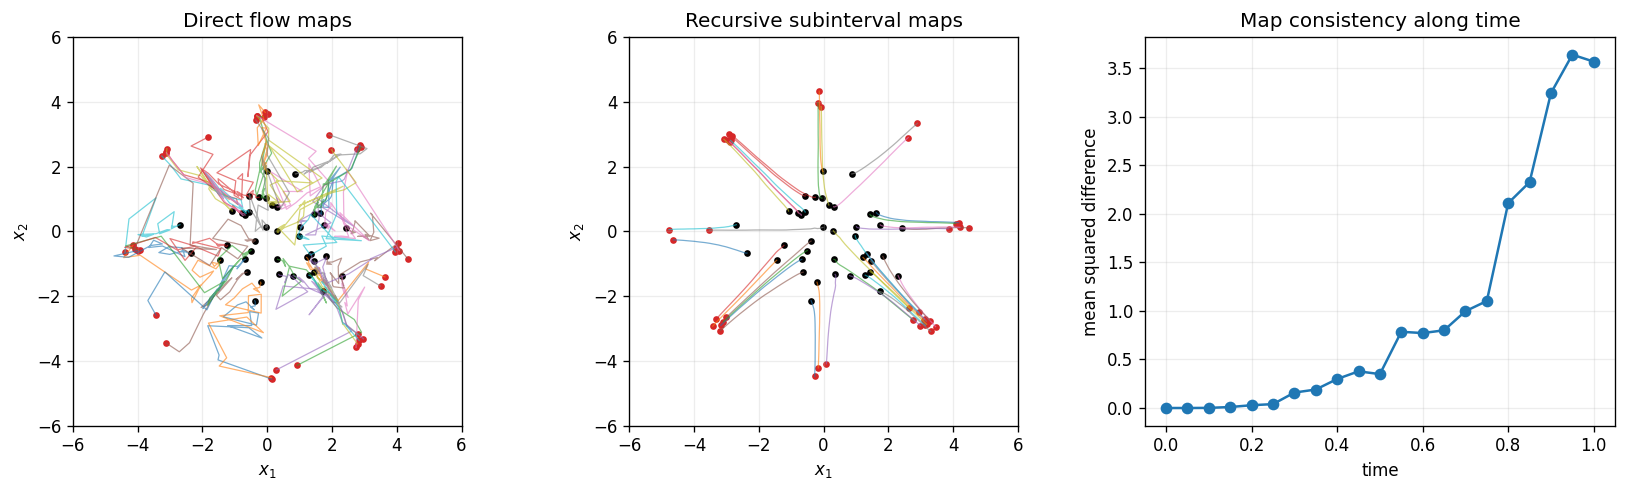

In [10]:
@torch.no_grad()
def direct_meanflow_path(model, initial, steps=20):
    """每个时刻都从同一 x0 直接调用区间 (0,t) 的平均速度。

    这不是递推轨迹；第 i 个点为 x0+t_i*u(x0,0,t_i)。若模型表示精确流映射，
    它应与逐段递推到 t_i 的状态一致。
    """
    outputs = []
    zero = torch.zeros(len(initial), 1, device=DEVICE)
    for index in range(steps+1):
        t = torch.full_like(zero, index/steps)
        outputs.append(initial+t*model(initial, zero, t))
    return torch.stack(outputs)


set_seed(SEED+500)
trajectory_initial = sample_noise(40)
direct_path = direct_meanflow_path(meanflow_model, trajectory_initial, 20)
recursive_path = sample_meanflow(meanflow_model, trajectory_initial, 20, keep_path=True)
# 先对二维坐标求平方距离，再对样本平均，保留每个时刻的误差。
per_time_consistency = (direct_path-recursive_path).square().sum(dim=-1).mean(dim=1)
flow_consistency_error = float(per_time_consistency.mean())
print(f"Direct vs recursive mean squared path error: {flow_consistency_error:.7f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, paths, title in zip(
    axes[:2], [direct_path, recursive_path], ["Direct flow maps", "Recursive subinterval maps"],
):
    values = paths.cpu().numpy()
    for index in range(len(trajectory_initial)):
        ax.plot(values[:, index, 0], values[:, index, 1], linewidth=0.75, alpha=0.6)
    ax.scatter(values[0, :, 0], values[0, :, 1], s=9, color="black")
    ax.scatter(values[-1, :, 0], values[-1, :, 1], s=9, color="tab:red")
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-6, 6), ylim=(-6, 6))
    ax.set_aspect("equal")
axes[2].plot(np.linspace(0, 1, 21), per_time_consistency.cpu().numpy(), marker="o")
axes[2].set(title="Map consistency along time", xlabel="time", ylabel="mean squared difference")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"05_flow_map_consistency.png", dpi=170, bbox_inches="tight")
plt.show()

## 6. 已知流映射上的平均速度监督验证

八高斯没有方便的解析概率流终点，因此最后回到线性 ODE $\dot x=Ax$。随机采样 $(x_s,s,t)$，直接监督网络拟合

$$
u^*(x_s,s,t)=\frac{e^{A(t-s)}x_s-x_s}{t-s}.
$$

比较一次平均速度更新和一次瞬时速度 Euler 的终点误差。如果网络确实学会平均速度，尤其在长区间上应显著优于 Euler。

In [11]:
A = torch.tensor([[0.5, -1.0], [1.0, 0.2]], device=DEVICE, dtype=DTYPE)


def batched_linear_flow(x, delta):
    """批量计算 exp(A*delta)x；matrix_exp 支持 [B,2,2] 矩阵批次。"""
    matrices = torch.matrix_exp(A[None]*delta[:, :, None])
    return torch.bmm(matrices, x[:, :, None]).squeeze(-1)


def exact_linear_average(x, delta):
    """线性 ODE 的真实有限区间平均速度。"""
    return (batched_linear_flow(x, delta)-x)/delta


set_seed(SEED+700)
supervised_meanflow = MeanFlowNet().to(DEVICE)
optimizer = torch.optim.Adam(supervised_meanflow.parameters(), lr=1e-3)
supervised_losses = []
for step in range(1, 2_001):
    x = torch.randn(BATCH_SIZE, 2, device=DEVICE)
    s = 0.8*torch.rand(BATCH_SIZE, 1, device=DEVICE)
    # 保持 delta>0.02，避免用极小位移相减再除法导致数值消减。
    delta = 0.02+(1-s-0.02)*torch.rand(BATCH_SIZE, 1, device=DEVICE)
    target = exact_linear_average(x, delta)
    loss = F.mse_loss(supervised_meanflow(x, s, delta), target)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    supervised_losses.append(float(loss.detach()))
    if step % 500 == 0:
        print(f"supervised average velocity step {step:4d}/2000: loss={np.mean(supervised_losses[-200:]):.7f}")

with torch.no_grad():
    test_x = torch.randn(10_000, 2, device=DEVICE)
    test_s = 0.8*torch.rand(10_000, 1, device=DEVICE)
    test_delta = 0.1+(1-test_s-0.1)*torch.rand(10_000, 1, device=DEVICE)
    exact_endpoint = batched_linear_flow(test_x, test_delta)
    # 同一初始点和区间下，比较平均速度一步更新与瞬时速度一步 Euler。
    meanflow_endpoint = test_x+test_delta*supervised_meanflow(test_x, test_s, test_delta)
    euler_endpoint = test_x+test_delta*(test_x@A.T)
    meanflow_endpoint_mse = float((meanflow_endpoint-exact_endpoint).square().mean())
    euler_endpoint_mse = float((euler_endpoint-exact_endpoint).square().mean())
print(f"Learned average-velocity endpoint MSE: {meanflow_endpoint_mse:.8f}")
print(f"Instantaneous Euler endpoint MSE     : {euler_endpoint_mse:.8f}")

supervised average velocity step  500/2000: loss=0.0019646


supervised average velocity step 1000/2000: loss=0.0005784


supervised average velocity step 1500/2000: loss=0.0002176


supervised average velocity step 2000/2000: loss=0.0001183


Learned average-velocity endpoint MSE: 0.00004819
Instantaneous Euler endpoint MSE     : 0.02033290


In [12]:
# 保存可机器读取的指标和全部模型参数，便于后续复现实验或继续消融。
artifact = {
    "config": {
        "seed": SEED,
        "train_steps": TRAIN_STEPS,
        "off_diagonal_probability": OFF_DIAG_PROB,
        "loss_power": LOSS_P,
    },
    "distribution_metrics": distribution_metrics,
    "flow_consistency_error": flow_consistency_error,
    "linear_identity_error": identity_error,
    "linear_endpoint_reconstruction_error": endpoint_error,
    "supervised_linear_meanflow_endpoint_mse": meanflow_endpoint_mse,
    "linear_euler_endpoint_mse": euler_endpoint_mse,
}
with open(OUTPUT_DIR/"metrics.json", "w", encoding="utf-8") as file:
    json.dump(artifact, file, indent=2, ensure_ascii=False)
torch.save({
    "meanflow": meanflow_model.state_dict(),
    "fm": fm_model.state_dict(),
    "wrong_jvp": wrong_jvp_model.state_dict(),
    "diagonal_only": diagonal_model.state_dict(),
    "unweighted": unweighted_model.state_dict(),
    "supervised_linear_meanflow": supervised_meanflow.state_dict(),
}, OUTPUT_DIR/"models.pt")
print("Saved figures, metrics, and model weights to", OUTPUT_DIR.resolve())

Saved figures, metrics, and model weights to /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/meanflow_outputs


## 7. 本次运行结果与结论

### 公式与已知流映射验证

- MeanFlow 恒等式最大误差：$2.665\times10^{-15}$；
- 用解析平均速度重建终点的最大误差：$4.441\times10^{-16}$；
- 监督学习线性 ODE 平均速度后的终点 MSE：$4.819\times10^{-5}$；
- 同一任务的一步瞬时速度 Euler MSE：$2.033\times10^{-2}$。

这说明 MeanFlow 恒等式、正号和 JVP 方向正确；当平均速度本身预测准确时，一步更新确实能显著优于瞬时速度 Euler。

### 八高斯生成指标

| 方法 | NFE | MMD² ↓ | SWD ↓ |
|---|---:|---:|---:|
| MeanFlow | 1 | 0.035469 | 0.565420 |
| MeanFlow | 2 | 0.016285 | 0.404719 |
| MeanFlow | 4 | 0.018649 | 0.434954 |
| MeanFlow | 8 | 0.011655 | 0.277706 |
| MeanFlow | 16 | 0.010611 | 0.251104 |
| FM | 1 | 0.703850 | 2.383814 |
| FM | 4 | 0.015021 | 0.346578 |
| FM | 32 | **0.003684** | **0.204753** |
| Wrong JVP | 1 | 0.126368 | 0.990415 |
| Diagonal only | 1 | 0.009108 | 0.295289 |
| Unweighted | 1 | 0.433747 | 66.491615 |

### 可以得到的判断

1. **MeanFlow 明显改善了一步生成。** `MeanFlow-1` 比 `FM-1` 好很多，并已经形成八个模态；说明有限区间训练提供了普通一步 Euler 没有的信息。
2. **本轮 MeanFlow 一步仍不是最佳生成结果。** FM 使用 4 步后已达到相近或更好的 MMD，32 步 FM 最好；MeanFlow 增加 NFE 后整体改善，但 2 到 4 步并不单调。
3. **JVP 的完整方向有实际作用。** 错误方向将一步 MMD 从 0.0355 恶化到 0.1264，说明只保留空间方向导数不足以替代 $(V,1,-1)$。
4. **普通 MSE 的 bootstrap MeanFlow 在本配置下发散。** `Unweighted` 的训练 loss 剧烈增长，SWD 达到 66.49；固定坐标图中的空白面板表示样本几乎全部跑出显示范围。自适应权重在这里承担了关键的稳定作用。
5. **`Diagonal only` 的好结果需要谨慎解释。** 它从未训练 $\Delta>0$，却得到很低的一步 MMD。这不是“只学瞬时速度即可得到平均速度”的理论证明。当前 Fourier 编码在 $\Delta=0$ 与 $\Delta=1$ 的正余弦分量相同，同时自适应加权改变了条件回归的总体最优解，因此可能产生有利但偶然的区间外推。需要更换非周期混淆的时间编码并运行多随机种子验证。
6. **主模型还没有学到严格的流组合性质。** 直接完整区间映射与 20 个递推子区间映射的平均路径误差为 0.9913，并在接近终点时快速增大。一步分布尚可不代表所有区间映射彼此一致。

因此，本轮最稳妥的结论是：**平均速度的一步生成原理成立，正确 JVP 和自适应稳定机制很重要；当前小模型训练已经获得有用的一步生成，但距离准确、一致的 MeanFlow 流映射仍有明显差距。**

### 输出文件

- `02_training_losses.png`：主训练与消融损失；
- `03_quality_vs_nfe.png`：MeanFlow/FM 的生成质量随 NFE 变化；
- `04_generated_distributions.png`：目标、主模型和三项消融的二维分布；
- `05_flow_map_consistency.png`：直接与递推流映射及逐时刻误差；
- `metrics.json`：所有生成指标和解析验证结果；
- `models.pt`：六个训练模型的权重。